Estimation error and backtest

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf

from quantlab.data_loader import load_prices
from quantlab.returns import log_returns
from quantlab.covariance import sample_cov, ledoit_wolf, ewma_cov, mp_edges, mp_density
from quantlab.simulation import one_factor_cov, excess_variance_study

stocks = log_returns(load_prices()).drop(columns="^GSPC")
print(stocks.shape)

(6537, 25)


250 edges: 0.47 1.73 | eigenvalues: 0.48 1.55
2500 edges: 0.81 1.21 | eigenvalues: 0.86 1.18


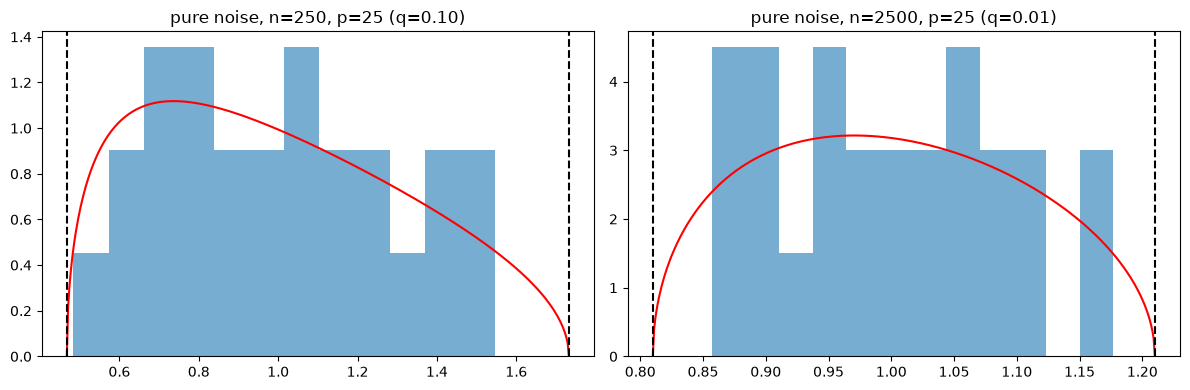

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, n in zip(ax, [250, 2500]):
    X = np.random.default_rng(0).standard_normal((n, 25))
    eig = np.linalg.eigvalsh(np.corrcoef(X, rowvar=False))
    lo, hi = mp_edges(n, 25)
    grid = np.linspace(lo, hi, 400)
    a.hist(eig, bins=12, density=True, alpha=0.6)
    a.plot(grid, mp_density(grid, n, 25), "r")
    a.axvline(lo, color="k", ls="--")
    a.axvline(hi, color="k", ls="--")
    a.set_title(f"pure noise, n={n}, p=25 (q={25 / n:.2f})")
    print(n, "edges:", round(lo, 2), round(hi, 2), "| eigenvalues:", eig.min().round(2), eig.max().round(2))
plt.tight_layout()
plt.show()

last 250 days | upper edge: 1.73 | largest eigenvalues: [7.94 3.41 1.48 1.3 ] | above edge: 2
full sample | upper edge: 1.13 | largest eigenvalues: [9.31 1.86 1.57 1.1 ] | above edge: 3


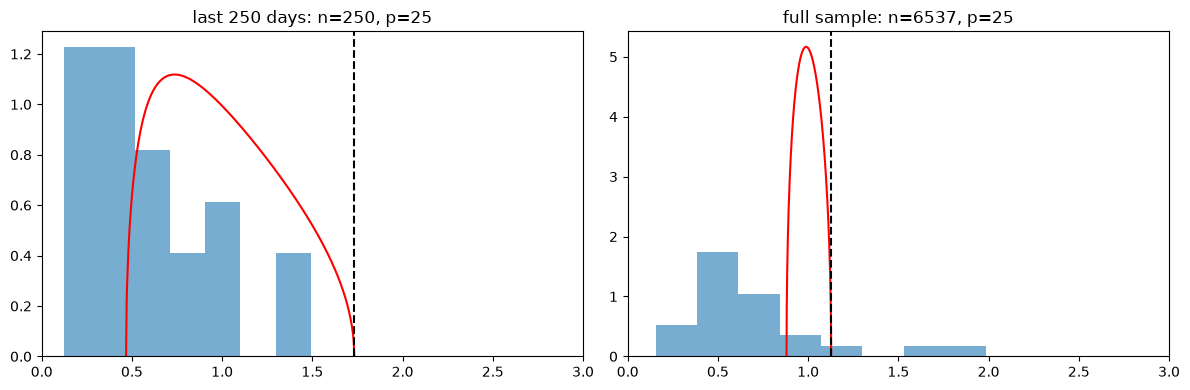

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (label, X) in zip(ax, [("last 250 days", stocks.iloc[-250:]), ("full sample", stocks)]):
    n, p = X.shape
    eig = np.linalg.eigvalsh(np.corrcoef(X.to_numpy(), rowvar=False))
    lo, hi = mp_edges(n, p)
    grid = np.linspace(lo, hi, 400)
    a.hist(eig, bins=40, density=True, alpha=0.6)
    a.plot(grid, mp_density(grid, n, p), "r")
    a.axvline(hi, color="k", ls="--")
    a.set_xlim(0, 3)
    a.set_title(f"{label}: n={n}, p={p}")
    print(label, "| upper edge:", round(hi, 2), "| largest eigenvalues:", np.sort(eig)[::-1][:4].round(2),
          "| above edge:", int((eig > hi).sum()))
plt.tight_layout()
plt.show()

In [5]:
for label, X in [("last 250 days", stocks.iloc[-250:]), ("full sample", stocks)]:
    A = X.to_numpy()
    S_lw, delta = ledoit_wolf(A)
    lw = LedoitWolf().fit(A)
    print(f"{label}: delta = {delta:.3f} (sklearn {lw.shrinkage_:.3f}), "
          f"max diff = {np.abs(S_lw - lw.covariance_).max():.1e}, "
          f"cond sample = {np.linalg.cond(sample_cov(A)):.0f}, cond LW = {np.linalg.cond(S_lw):.0f}")

last 250 days: delta = 0.139 (sklearn 0.139), max diff = 0.0e+00, cond sample = 109, cond LW = 34
full sample: delta = 0.006 (sklearn 0.006), max diff = 0.0e+00, cond sample = 89, cond LW = 85


In [6]:
true_cov = one_factor_cov(25, seed=0)
study = excess_variance_study(true_cov, ns=(60, 120, 250, 500, 1000), reps=500, seed=0)

print("Excess-variance ratio (1 = perfect):")
display(study.pivot(index="n", columns="estimator", values="ratio").round(3))
print("Condition number of the estimate:")
display(study.pivot(index="n", columns="estimator", values="cond").round(0))

Excess-variance ratio (1 = perfect):


estimator,ewma,ledoit_wolf,sample
n,,,
60,1.984,1.335,1.689
120,1.948,1.196,1.259
250,1.941,1.098,1.109
500,1.954,1.048,1.051
1000,1.939,1.023,1.024


Condition number of the estimate:


estimator,ewma,ledoit_wolf,sample
n,,,
60,251.0,61.0,155.0
120,230.0,53.0,73.0
250,229.0,46.0,51.0
500,230.0,42.0,44.0
1000,227.0,40.0,41.0


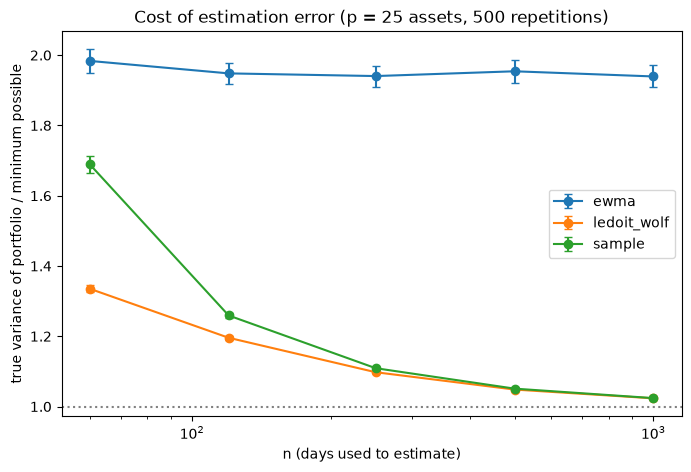

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in study.groupby("estimator"):
    ax.errorbar(g["n"], g["ratio"], yerr=2 * g["ratio_se"], marker="o", capsize=3, label=name)
ax.axhline(1, color="grey", ls=":")
ax.set_xscale("log")
ax.set_xlabel("n (days used to estimate)")
ax.set_ylabel("true variance of portfolio / minimum possible")
ax.set_title("Cost of estimation error (p = 25 assets, 500 repetitions)")
ax.legend()
plt.show()

## Conclusions (Part 1: estimation error)

**1. Marchenko-Pastur on pure noise.** For independent noise with p = 25, the sample correlation eigenvalues stay inside the predicted edges. With n = 250 (q = 0.10) the edges are 0.47 and 1.73 and the observed eigenvalues run from 0.48 to 1.55. With n = 2,500 (q = 0.01) the edges tighten to 0.81 and 1.21 and the observed range is 0.86 to 1.18. Even when the truth is the identity matrix, the sample eigenvalues are spread out: with 250 days the smallest comes out near half of the true value and the largest well above it. The spread shrinks as n grows relative to p.

**2. Real data against the edge.** In the last 250 days, the upper edge is 1.73, and two eigenvalues lie above it (7.94 and 3.41). The next two (1.48 and 1.30) are inside the bulk, so they cannot be separated from noise. In the full sample (n = 6,537), the edge is much tighter at 1.13, and three eigenvalues exceed it (9.31, 1.86 and 1.57). The largest eigenvalue is the market factor: 9.31 out of a total of 25 means it carries about 37% of the variance, consistent with the 38.6% PC1 share found in the PCA drill. The smaller eigenvalues above the edge probably reflect sector or period effects. Eigenvalues inside the bulk should not be trusted individually. A portfolio optimiser that uses them is fitting noise.

**3. Ledoit-Wolf on real data.** My implementation matches scikit-learn exactly (maximum difference 0.0 in both windows, and the same shrinkage values). With 250 days the intensity is δ = 0.139, so the estimate moves 14% of the way toward the scaled identity, and the condition number falls from 109 to 34. With the full sample, δ = 0.006 and the condition number is almost unchanged (89 to 85). Shrinkage matters when the sample is short relative to the number of assets (p/n = 0.10 here) and is almost irrelevant when it is long (p/n = 0.004).

**4. Simulation with a known truth (excess-variance ratio, 1 = perfect).** Building the minimum-variance portfolio from a sample covariance of 60 days gives a portfolio with 69% more true variance than the best possible one (ratio 1.689). Ledoit-Wolf reduces this to 1.335. At n = 120 the figures are 1.259 and 1.196, at n = 250 they are 1.109 and 1.098, and at n = 1,000 they are 1.024 and 1.023. Both converge to 1 as n grows, and Ledoit-Wolf is never worse than the sample estimator. The benefit is large when n is small and negligible when n is large, which agrees with the shrinkage intensities found on the real data. Condition numbers tell the same story: at n = 60 the sample covariance averages 155 and Ledoit-Wolf 61. The standard errors on these ratios are small (below 0.02), so the ordering is not a fluke of the draws.

**5. EWMA.** EWMA stays at a ratio of about 1.94 to 1.98 for every n, with a condition number of about 230, and does not improve as the sample grows. With λ = 0.94 the effective sample is only about 1/(1-λ) ≈ 17 days, which is fewer than the 25 assets, so its estimate stays noisy however much data is available. In this simulation the true covariance never changes, so EWMA's strength (reacting to changing volatility) cannot show. This says nothing yet about real data, where volatility clusters. Whether EWMA wins there is an empirical question for the backtest.

**6. Limits of this evidence.** The simulation uses Normal data, a stationary one-factor covariance and 25 assets. Real returns have fat tails and clustered volatility, so real estimation errors are probably larger than shown. The study also covers only the covariance matrix. The means, which drove the extreme tangency weights, are estimated with much more error and have not been tested here.

## Part 2: Walk-forward backtest

**Settings fixed before looking at results.** Simple returns of the 25 stocks. Estimation window 504 days (about 2 years), rebalance every 21 days (monthly), transaction cost 10 bps (0.001) per unit of turnover. Zero risk-free rate. Sharpe ratios are annualised. Shrunk mean-variance uses Ledoit-Wolf covariance, k = 0.5 shrinkage of means toward the cross-sectional average, and falls back to minimum variance when the tangency weights are invalid or exceed 3 in gross exposure. Sensitivity: window 252, rebalance 63, costs of 0 and 30 bps. Everything is reported, whichever strategy wins.

In [8]:
from quantlab.returns import simple_returns
from quantlab.backtest import (
    walk_forward, equal_weight, minvar_sample, minvar_lw, minvar_lw_long_only, make_shrunk_mv,
)
from quantlab.metrics import summary, wealth, drawdown, sharpe

rets = simple_returns(load_prices()).drop(columns="^GSPC")
print(rets.shape)

def make_strategies():
    return {
        "1/N": equal_weight,
        "MinVar sample": minvar_sample,
        "MinVar LW": minvar_lw,
        "MinVar LW long-only": minvar_lw_long_only,
        "Shrunk MV": make_shrunk_mv(k=0.5),
    }

(6537, 25)


In [9]:
strategies = make_strategies()
results = {name: walk_forward(rets, fn, window=504, rebalance=21, cost=0.001)
           for name, fn in strategies.items()}

table = summary(results)
print("Shrunk MV fallbacks:", strategies["Shrunk MV"].stats)
table.round(3)

Shrunk MV fallbacks: {'calls': 288, 'fallbacks': 152}


,ann_return,ann_vol,sharpe,max_drawdown,turnover_per_year,ann_return_gross,sharpe_gross
1/N,0.146,0.186,0.823,-0.438,0.582,0.146,0.826
MinVar sample,0.075,0.145,0.571,-0.402,3.299,0.078,0.594
MinVar LW,0.080,0.144,0.609,-0.375,2.832,0.083,0.629
MinVar LW long-only,0.095,0.145,0.698,-0.353,1.468,0.096,0.708
Shrunk MV,0.110,0.163,0.725,-0.375,8.426,0.120,0.777


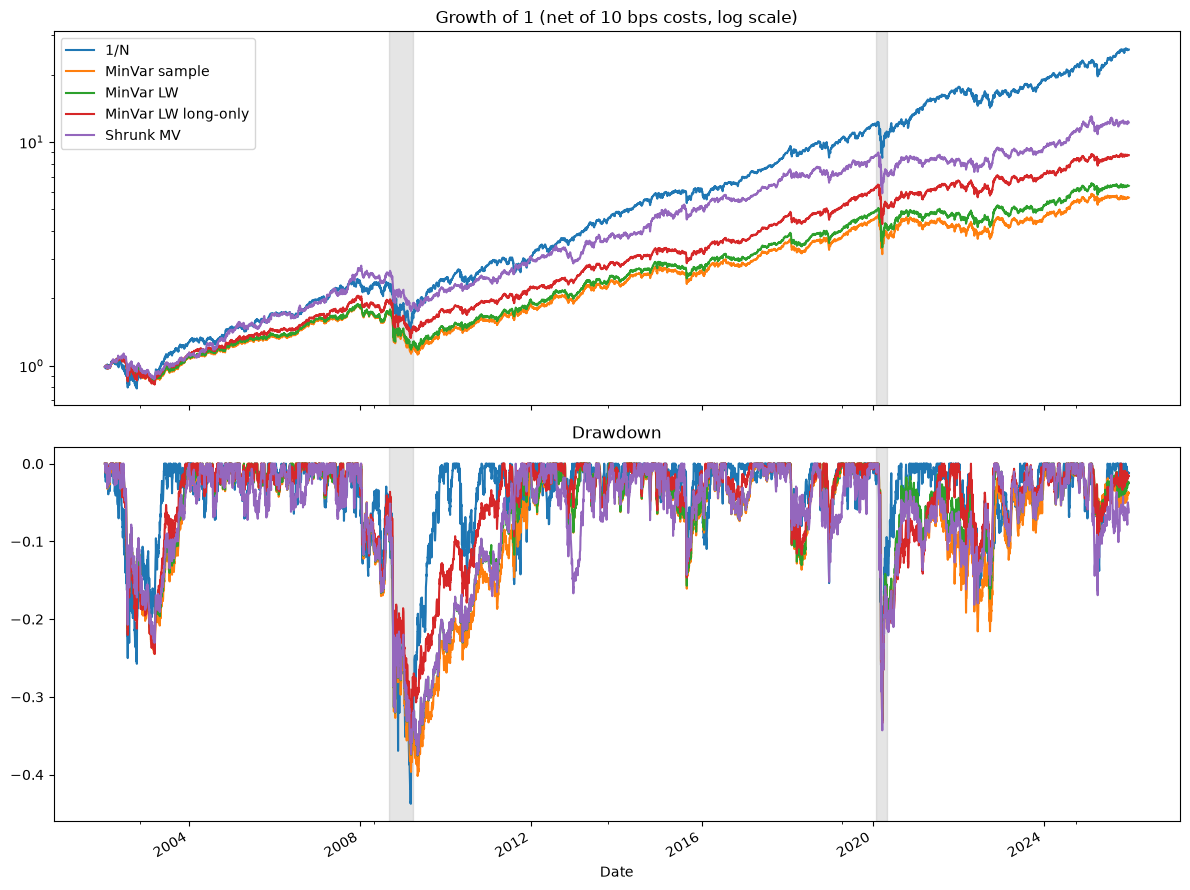

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for name, res in results.items():
    wealth(res["ret"]).plot(ax=ax[0], label=name)
    drawdown(res["ret"]).plot(ax=ax[1], label=name)
ax[0].set_yscale("log")
ax[0].set_title("Growth of 1 (net of 10 bps costs, log scale)")
ax[1].set_title("Drawdown")
for a in ax:
    a.axvspan(pd.Timestamp("2008-09-01"), pd.Timestamp("2009-03-31"), color="grey", alpha=0.2)
    a.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2020-04-30"), color="grey", alpha=0.2)
ax[0].legend()
plt.tight_layout()
plt.show()

In [11]:
settings = [
    dict(window=252, rebalance=21, cost=0.001),
    dict(window=504, rebalance=63, cost=0.001),
    dict(window=504, rebalance=21, cost=0.0),
    dict(window=504, rebalance=21, cost=0.003),
]
rows = {}
for s in settings:
    label = f"W{s['window']}/R{s['rebalance']}/{s['cost'] * 1e4:.0f}bp"
    rows[label] = {name: sharpe(walk_forward(rets, fn, **s)["ret"])
                   for name, fn in make_strategies().items()}
sens = pd.DataFrame(rows).T
display(sens.round(3))
print("Rank by Sharpe (1 = best):")
display(sens.rank(axis=1, ascending=False).astype(int))

,1/N,MinVar sample,MinVar LW,MinVar LW long-only,Shrunk MV
W252/R21/10bp,0.805,0.566,0.625,0.698,0.621
W504/R63/10bp,0.827,0.579,0.613,0.699,0.745
W504/R21/0bp,0.826,0.594,0.629,0.708,0.777
W504/R21/30bp,0.817,0.526,0.570,0.677,0.620


Rank by Sharpe (1 = best):


,1/N,MinVar sample,MinVar LW,MinVar LW long-only,Shrunk MV
W252/R21/10bp,1,5,3,2,4
W504/R63/10bp,1,5,4,3,2
W504/R21/0bp,1,5,4,3,2
W504/R21/30bp,1,5,4,2,3


In [13]:
periods = {"2002-2009": ("2002", "2009"), "2010-2019": ("2010", "2019"), "2020-2025": ("2020", "2025")}
by_period = pd.DataFrame({
    label: {name: sharpe(res["ret"].loc[a:b]) for name, res in results.items()}
    for label, (a, b) in periods.items()
}).T
display(by_period.round(3))

years = len(results["1/N"]) / 252
se = {name: np.sqrt((1 + 0.5 * sharpe(res["ret"]) ** 2) / years) for name, res in results.items()}
print(f"Years: {years:.1f}. Approximate standard error of each Sharpe ratio (i.i.d. approximation):")
print(pd.Series(se).round(2))

,1/N,MinVar sample,MinVar LW,MinVar LW long-only,Shrunk MV
2002-2009,0.606,0.337,0.370,0.509,0.643
2010-2019,1.188,1.122,1.157,1.204,1.100
2020-2025,0.768,0.308,0.357,0.438,0.411


Years: 23.9. Approximate standard error of each Sharpe ratio (i.i.d. approximation):
1/N                    0.24
MinVar sample          0.22
MinVar LW              0.22
MinVar LW long-only    0.23
Shrunk MV              0.23
dtype: float64


### Limitations (write plainly)
- Survivorship bias: the 25 stocks are today's large caps, so firms that failed or were dropped are missing. This flatters every strategy, especially around 2008.
- One market, one universe, one sample period; results may not carry over.
- Sharpe ratios over ~24 years have a standard error of about 0.2, so close rankings are not evidence.
- Window, rebalance frequency, cost level and shrinkage constants were fixed in advance; the sensitivity table shows how much rankings move.
- The shrunk mean-variance strategy partly falls back to minimum variance; the fallback count is reported.

## Conclusions (Part 2: walk-forward backtest)

**1. Main result.** With a 504-day window, monthly rebalancing and 10 bps costs, the equal-weight (1/N) portfolio has the best Sharpe ratio (0.823) and the highest return (14.6% a year, volatility 18.6%). The others are: long-only Ledoit-Wolf minimum variance 0.698, shrunk mean-variance 0.725, Ledoit-Wolf minimum variance 0.609 and sample minimum variance 0.571. The minimum-variance strategies did reduce volatility as intended (about 14.5% against 18.6%), but they gave up more return than they saved in risk, so their Sharpe ratios are lower. Maximum drawdowns are large for all strategies (-35% to -44%), and 1/N is the worst at -43.8%, so the lower-volatility strategies protected only modestly in the worst episodes.

**2. Does shrinkage help?** Yes, modestly and consistently. Ledoit-Wolf beats the sample covariance for minimum variance in all four settings: Sharpe 0.609 against 0.571 in the main run, and ahead by 0.034 to 0.059 in every sensitivity row. It also has a smaller drawdown (-37.5% against -40.2%) and lower turnover (2.83 against 3.30 a year). This matches the simulation, where shrinkage gave the larger benefit at small n/p. But the gains are small relative to the uncertainty in point 6.

**3. The long-only constraint helped more than shrinkage.** Long-only Ledoit-Wolf has Sharpe 0.698 against 0.609 for the unconstrained version, the smallest drawdown of all (-35.3%), and half the turnover (1.47 against 2.83). It is ahead of the unconstrained version in all four settings. The extreme short positions that the closed-form solution allows are another way estimation error shows up in practice.

**4. Shrunk mean-variance is unstable, and mostly a hybrid.** The strategy fell back to minimum variance in 152 of 288 rebalances (53%), so about half the time it is not a mean-variance portfolio at all. It has by far the highest turnover (8.4 a year, about 14 times that of 1/N), which costs it 0.05 of Sharpe (0.777 gross, 0.725 net), and at 30 bps costs its Sharpe falls to 0.620. Its rank changes across settings: 4th with a 252-day window, 2nd with quarterly rebalancing and at zero cost, 3rd at 30 bps. Ranks that move this much are not evidence of a real advantage.

**5. Robustness of the ranking.** 1/N ranks first in all four sensitivity settings, and sample minimum variance is last in all four. Everything in between depends on the setting. Transaction costs matter most for the high-turnover strategies: from 0 to 30 bps, 1/N's Sharpe barely moves (0.826 to 0.817), while shrunk mean-variance drops from 0.777 to 0.620.

**6. Statistical caution.** The approximate standard error of each Sharpe ratio is about 0.22 to 0.24 over 23.9 years. 1/N leads sample minimum variance by about 0.25, roughly one standard error, and leads the others by 0.10 to 0.21, which is less than one. With these numbers I cannot claim that 1/N is truly better, only that it was not beaten. These strategies are correlated, so the uncertainty of a difference is smaller than the uncertainty of each Sharpe on its own, but quantifying that needs a paired or block-bootstrap test, which is a Phase 2 item.

**7. The result depends on the period.** In 2002-2009, shrunk mean-variance (0.643) and 1/N (0.606) are ahead of the minimum-variance strategies (0.34 to 0.51). In 2010-2019 all five are close (1.10 to 1.20) and long-only minimum variance is nominally best (1.204). In 2020-2025 1/N has a clear lead (0.768 against 0.31 to 0.44). Much of 1/N's overall advantage therefore comes from the last six years. A plausible reason is that the low-volatility stocks these strategies favour lagged the rest, but I have not tested this.

**8. What this says about the project question.** The honest conclusion is that none of the optimised strategies reliably beat the equal-weight benchmark out of sample. Ledoit-Wolf shrinkage and a long-only constraint both improved on naive sample minimum variance, in line with the finding of DeMiguel, Garlappi and Uppal (2009) that estimation error limits optimisation, but the improvements are within the noise of the data, and the winning benchmark may partly reflect how the universe was chosen (today's survivors, which includes large long-run winners). The simple rule is hard to beat; shrinkage and constraints narrow the gap.